<a href="https://colab.research.google.com/github/naxxovvv/proyecto-paes-pucv/blob/main/ajuste_paes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ajuste de la tabla PAES Ciencias - Física (Forma 163)


In [ ]:
!git clone https://github.com/naxxovvv/proyecto-paes-pucv
%cd proyecto-paes-pucv

Cloning into 'proyecto-paes-pucv'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 17 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 479.52 KiB | 43.59 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/proyecto-paes-pucv


In [ ]:
import os
os.makedirs('figuras', exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

## 1. Leer los datos desde el archivo

In [ ]:
# delimiter="," porque las columnas estan separadas por comas.
# skiprows=2 para que saltemos las 2 primeras lineas (el comentario de la fuente y los titulos "P,PAES").
datos = np.loadtxt("datos_paes_fisica.csv", delimiter=",", skiprows=2)

# Separamos las dos columnas: la primera que tendremos será P (respuestas correctas) y la segunda es el puntaje PAES.
P_todos = datos[:, 0]
PAES_todos = datos[:, 1]

# CASO BORDE: el dato P = 75 (1000 puntos) es un salto raro (de 930 a 1000), asi que no lo usamos para ajustar. [:-1] es decir, usamremos para para todos los datos menos el ultimo que no nos interesa en el analisis.
P = P_todos[:-1]
PAES = PAES_todos[:-1]

# Los puntajes del DEMRE estan redondeados a numeros enteros, asi que suponemos que cada dato puede tener un error de +-0.5 puntos.
error = 0.5

## 2. Las tres funciones que vamos a probar

In [ ]:
# Cada funcion recibe x (el puntaje bruto P) y los parametros a, b, c, ...
# Los parametros son los numeros que curve_fit va a buscar por nosotros.

def polinomio3(x, a, b, c, d):
    # Polinomio de grado 3: la curva mas simple que puede hacer una forma de "S"
    return a + b * x + c * x**2 + d * x**3


def polinomio5(x, a, b, c, d, e, f):
    # Polinomio de grado 5: lo mismo pero con mas terminos (es un poco mas flexible)
    return a + b * x + c * x**2 + d * x**3 + e * x**4 + f * x**5


def logit(x, a, b, c, d):
    # Funcion con logaritmo. La seleccione porque la tabla sube rapido al principio, casi se aplana en el medio y vuelve a subir rapido al final, y esta funcion se adapta parecida a esta curva. OJO: d tiene que ser mayor que 75, si no el logaritmo falla.
    return a + b * np.log((x + c) / (d - x))

## 3. Ajuste con curve_fit

In [ ]:
# Los valores iniciales (p0) son un "punto de partida" para que curve_fit empiece a buscar.
# Si se parten con numeros muy malos, el ajuste puede fallar.
# Para elegirlos miramos el grafico y estimamos los datos.
modelos = {
    "Polinomio grado 3": (polinomio3, [100, 20, 0, 0]),
    "Polinomio grado 5": (polinomio5, [100, 20, 0, 0, 0, 0]),
    "Logit": (logit, [540, 170, 6, 82]),
}

resultados = {}

for nombre, (funcion, p0) in modelos.items():
    # curve_fit busca los parametros que hacen que la funcion se acerque lo mas posible a los datos (metodo de minimos cuadrados). Devuelve los parametros en "params"
    params, cov = curve_fit(funcion, P, PAES, p0=p0, maxfev=100000)

    # "ajuste" son los valores que predice la funcion para cada P
    ajuste = funcion(P, *params)

    # (dato - ajuste) es el residuo; lo dividimos por el error, lo elevamos al cuadrado y sumamos todo. Menor chi2 = mejor ajuste.
    chi2 = np.sum(((PAES - ajuste) / error) ** 2)

    # divididimos por (datos - parametros) porque una funcion con mas parametros se ajusta mejor.
    grados_libertad = len(P) - len(params)
    chi2_red = chi2 / grados_libertad

    # R^2: que fraccion de la variacion de los datos explica la curva
    # Vale 1 si el ajuste es perfecto.
    ss_res = np.sum((PAES - ajuste) ** 2)             # suma de errores al cuadrado
    ss_tot = np.sum((PAES - np.mean(PAES)) ** 2)      # variacion total de los datos
    r2 = 1 - ss_res / ss_tot

    resultados[nombre] = (funcion, params)
    print(nombre)
    print("  parametros:", [float(f"{p:.5g}") for p in params])
    print(f"  chi2 = {chi2:.1f}   chi2 reducido = {chi2_red:.1f}   R2 = {r2:.4f}")
    print(f"  prediccion para P = 75: {funcion(75, *params):.0f}")

Polinomio grado 3
  parametros: [108.43, 19.386, -0.31422, 0.0027115]
  chi2 = 8453.8   chi2 reducido = 119.1   R2 = 0.9993
  prediccion para P = 75: 939
Polinomio grado 5
  parametros: [96.535, 24.314, -0.76788, 0.018553, -0.00023377, 1.2299e-06]
  chi2 = 4567.7   chi2 reducido = 66.2   R2 = 0.9996
  prediccion para P = 75: 950
Logit
  parametros: [540.54, 172.86, 6.0911, 82.502]
  chi2 = 5087.0   chi2 reducido = 71.6   R2 = 0.9996
  prediccion para P = 75: 952


## 4. Grafico

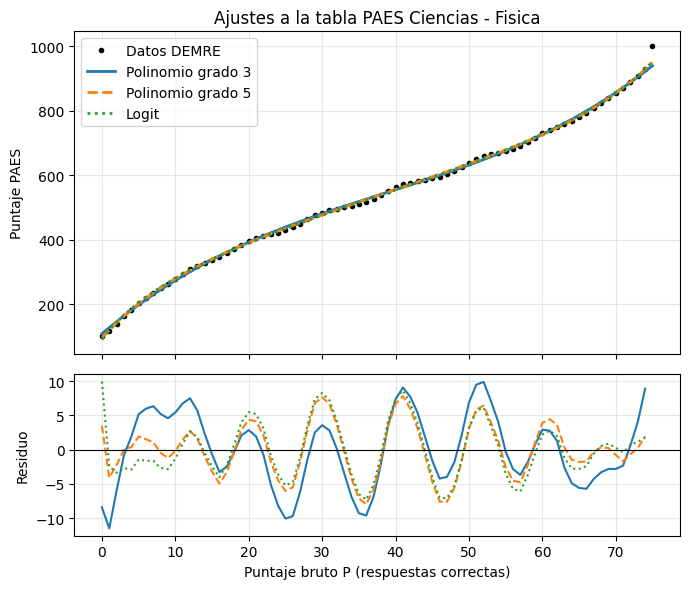

In [ ]:
# El grafico de residuos sirve porque las 3 curvas son casi iguales y se tapan entre ellas; en los residuos si se ven las diferencias.
x = np.linspace(0, 75, 300)   # 300 puntos entre 0 y 75 para dibujar curvas suaves
estilos = ["-", "--", ":"]    # un tipo de linea distinto para cada curva
colores = ["tab:blue", "tab:orange", "tab:green"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

ax1.plot(P_todos, PAES_todos, "ko", markersize=3, label="Datos DEMRE")

# Dibujamos cada curva (arriba) y su residuo (abajo)
for (nombre, (funcion, params)), est, col in zip(resultados.items(), estilos, colores):
    ax1.plot(x, funcion(x, *params), est, color=col, linewidth=2, label=nombre)
    ax2.plot(P, PAES - funcion(P, *params), est, color=col, linewidth=1.5)

ax1.set_ylabel("Puntaje PAES")
ax1.set_title("Ajustes a la tabla PAES Ciencias - Fisica")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_xlabel("Puntaje bruto P (respuestas correctas)")
ax2.set_ylabel("Residuo")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figuras/ajustes_paes.pdf")
plt.savefig("figuras/ajustes_paes.png", dpi=200)
plt.show()